# UTH Computer Vision Coursework — Topic 11
## Notebook 03: Real-Manifold Hard-Sample Mining & Benchmark Analytics
- **Nhóm thực hiện**: Nhóm 4
- **Đề tài**: *Stable Diffusion-Based Synthetic Facial Dataset Generation for Deepfake Detection*
- **Mục tiêu**: Phân tích các Mẫu Khó (`Hard Samples`) nằm sát đa tạp ảnh thật và kiểm tra các bộ benchmark đối chứng.

In [1]:
# --- [AUTOMATIC PROJECT ROOT SETUP] ---
import sys, os
from pathlib import Path
root_dir = Path.cwd()
while not (root_dir / 'src').exists() and root_dir != root_dir.parent:
    root_dir = root_dir.parent
if str(root_dir) not in sys.path:
    sys.path.insert(0, str(root_dir))
os.chdir(root_dir)
# --------------------------------------

import json
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

from src.common.config import load_config

print('Environment initialized successfully.')
print('Project Root: uth-cv-coursework')


Environment initialized successfully.
Project Root: uth-cv-coursework


### 1. Báo cáo thống kê toàn diện bộ dữ liệu (`paths.stats_file`)

In [2]:
cfg = load_config(Path('configs/dataset_factory.yaml'))
stats_path = Path(cfg['paths']['stats_file'])

if stats_path.exists():
    with open(stats_path, 'r', encoding='utf-8') as f:
        stats = json.load(f)
    print('Báo cáo thống kê tổng thể Dataset:')
    print(json.dumps(stats, indent=2))
else:
    print('File thống kê chưa được tạo. Chạy: python3 -m scripts.organize_topic_dataset')


Báo cáo thống kê tổng thể Dataset:
{
  "counts_by_source": {
    "raw_real": 4000,
    "synthetic_total": 2200,
    "curated_synthetic": 2200,
    "hard_samples": 740
  },
  "counts_by_mode": {
    "sd_img2img": 834,
    "sd_inpaint": 878,
    "sd_text2img": 488
  },
  "demographics": {
    "age_distribution": {
      "0-2": 137,
      "30-39": 932,
      "3-6": 341,
      "20-29": 1262,
      "40-49": 525,
      "50-69": 395,
      "10-14": 149,
      "15-19": 252,
      "7-9": 135,
      "70-120": 72,
      "young": 1576,
      "mature": 424
    },
    "gender_distribution": {
      "male": 2492,
      "female": 3708
    },
    "glasses_distribution": {
      "None": 5245,
      "Normal": 692,
      "Dark": 203,
      "Glasses": 60
    }
  },
  "curation_pass_rate": 1.0,
  "hard_rate_by_mode": {
    "sd_text2img": 0.05327868852459016,
    "sd_inpaint": 0.6583143507972665,
    "sd_img2img": 0.1630695443645084
  },
  "tau": null,
  "hardness_config": {
    "method": "real_manifold",
  

### 2. Phân bố Mẫu Khó theo từng chế độ sinh

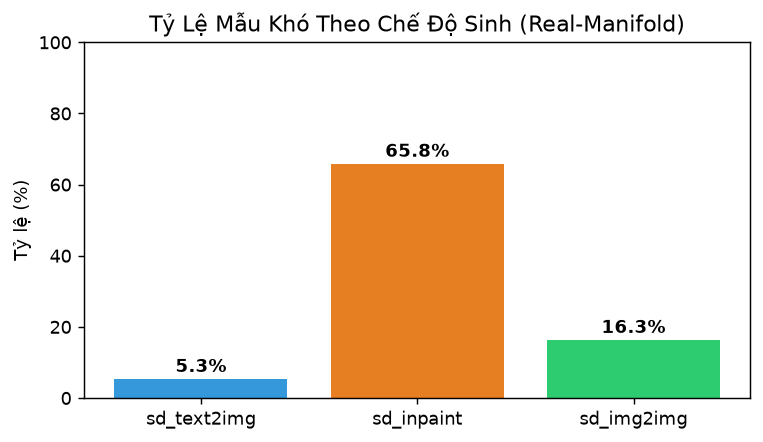

In [3]:
if stats_path.exists():
    hard_rates = stats.get('hard_rate_by_mode', {})
    if hard_rates:
        modes = list(hard_rates.keys())
        rates = [hard_rates[m] * 100.0 for m in modes]
        plt.figure(figsize=(6, 3.5))
        plt.bar(modes, rates, color=['#3498db', '#e67e22', '#2ecc71'])
        plt.title('Tỷ Lệ Mẫu Khó Theo Chế Độ Sinh (Real-Manifold)')
        plt.ylabel('Tỷ lệ (%)')
        plt.ylim([0, 100])
        plt.tight_layout()
        plt.show()


### 3. Lưới ảnh đối chứng trực quan toàn diện (Visual Gallery)

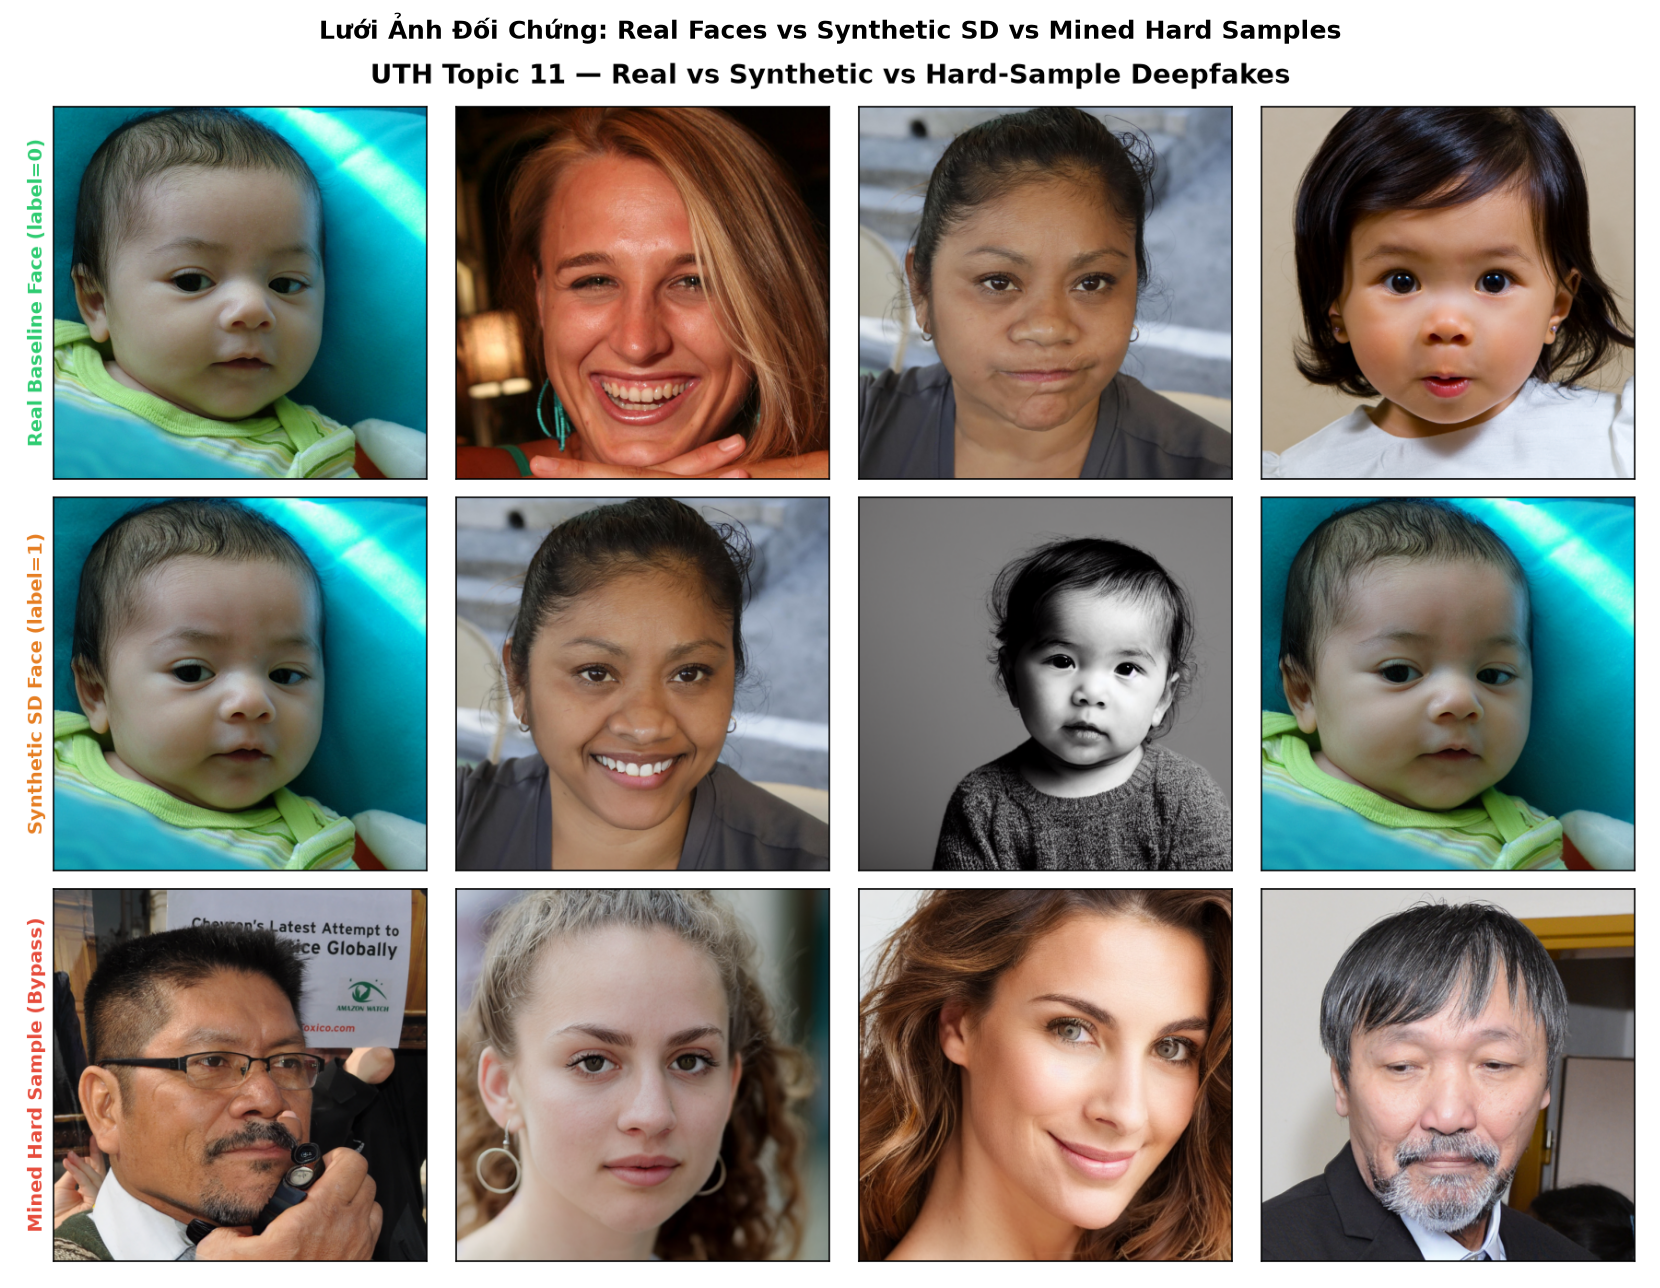

In [4]:
gallery_path = Path(cfg['paths']['gallery_image'])
if gallery_path.exists():
    im = Image.open(gallery_path)
    plt.figure(figsize=(14, 10))
    plt.imshow(im)
    plt.axis('off')
    plt.title('Lưới Ảnh Đối Chứng: Real Faces vs Synthetic SD vs Mined Hard Samples', fontsize=14, fontweight='bold')
    plt.show()
else:
    print('Chưa có file gallery, chạy: python3 -m scripts.build_visual_gallery')
